# 4 · Refining the graph

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vitormeriat/text4gcn/blob/main/docs/tutorials/04_refining_the_graph.ipynb)

Tutorial 3 showed that a graph with far fewer edges can classify almost as
well. Choosing a builder is one way to get there. **Graph refinement** is
another: it takes a graph that is already built and removes rare words and
weak edges before training, without rebuilding anything.

We first **measure** what each refinement removes, which takes seconds and
needs no training. Then we **train** on a few of the refined graphs.

> **Runtime:** about 2.5 min on a T4 GPU, almost all of it building the TF-IDF graph
> (about 2 min). Graph building runs on the CPU; a GPU speeds up only the training of
> the four models, which takes several times longer on CPU.

| # | Tutorial | Question it answers |
|---|---|---|
| 1 | Text as a graph | What does the graph look like, and why does it help? |
| 2 | Your first classifier | How do I go from raw text to test accuracy? |
| 3 | Choosing a graph builder | How should words be connected? |
| 4 | **Refining the graph** | Can a smaller graph do as well? |
| 5 | Bring your own corpus | How do I use my own (non-English) data? |

In [ ]:
%pip install -q text4gcn
# Release candidate from TestPyPI (dependencies still come from PyPI):
# %pip install -q -i https://test.pypi.org/simple/ --extra-index-url https://pypi.org/simple/ "text4gcn==2.0.0rc2"

In [2]:
import shutil
from pathlib import Path

import numpy as np
import pandas as pd

import text4gcn
from text4gcn import GNN, Builder, RefinementConfig, TextPipeline, apply_refinement
from text4gcn.builder import Frequency
from text4gcn.datasets import twenty_newsgroups
from text4gcn.models.utils import LoadData
from text4gcn.utils import check_pytorch_installation, get_device_manager

In [3]:
print("text4gcn:", text4gcn.__version__)
print(check_pytorch_installation())   # torch version, cuda_available, CUDA version
print(get_device_manager().get_device_info())  # device the GNN will use

text4gcn: 2.0.0rc2
{'torch_version': '2.11.0+cu130', 'cuda_available': True, 'cuda_version': '13.0'}
{'device': 'cuda', 'type': 'cuda', 'is_cuda': True, 'is_cpu': False, 'cuda_version': '13.0', 'gpu_name': 'Tesla T4', 'gpu_memory': 15637086208, 'gpu_memory_gb': 15.637086208}


In [4]:
NAME = "20NG4"
DATA_DIR = Path("data")
LOG_DIR = Path("logs")
SEED = 1234
CATEGORIES = ["alt.atheism", "soc.religion.christian", "comp.graphics", "sci.med"]

In [5]:
shutil.rmtree(DATA_DIR, ignore_errors=True)   # start clean: outputs of older runs would be reused
twenty_newsgroups(DATA_DIR, name=NAME, categories=CATEGORIES)
TextPipeline(dataset_name=NAME, dataset_path=DATA_DIR, seed=SEED).execute(validation_ratio=0.10)
Frequency(dataset_name=NAME, dataset_path=DATA_DIR).tfidf(window_size=20)

text4gcn · TextPipeline("20NG4") · language english · validation 10%
  ✓ clean     3,647 documents · 10,890 words kept (rare_count=5)  (0.8 s)
  ✓ shuffle   train 2,192 · test 1,455 documents (seed 1234)  (0.1 s)
  ✓ words     10,890 words · 9,179 with a WordNet definition  (5.4 s)
  ✓ features  train 1,973 · validation 219 · test 1,455 documents · 4 classes  (1.6 s)
text4gcn · Frequency.tfidf("20NG4") · window 20
  ✓ graph     14,537 nodes · 4.53 M edges (4.26 M word–word) · density 2.15% · 52.0 MiB  (2m05s)


GraphBuildStats(builder='frequency.tfidf', dataset='20NG4', nodes=14,537, edges=4,534,779, word_word=4,258,440, density=2.15%, size='52.0 MiB')

## The knobs

`RefinementConfig` combines node filters and edge pruning. Document nodes are
always kept (`keep_docs=True`), so the train, validation and test sets do not
change.

| Option | Removes |
|---|---|
| `min_doc_freq=k` | words that occur in fewer than $k$ documents |
| `max_doc_freq_ratio=r` | words that occur in more than a fraction $r$ of the documents |
| `edge_weight_threshold=w` | edges with a PMI or TF-IDF weight below $w$ |
| `top_k_edges_per_node=k` | all but the $k$ heaviest edges of each node |

See the [refinement guide](https://vitormeriat.github.io/text4gcn/guides/refinement/) for the full list.

## Measure before you train

`LoadData(...).load_corpus()` loads the graph and features that `GNN` would
train on. `apply_refinement(..., return_metadata=True)` returns the refined
graph together with statistics, without training.

In [6]:
predata = LoadData(path=DATA_DIR, dataset=NAME, builder=Builder.Tfidf).load_corpus()
weights = predata[0].tocsr().data          # PMI and TF-IDF weights of every edge

quantiles = pd.Series(np.quantile(weights, [0.1, 0.25, 0.5, 0.75, 0.9]),
                      index=["10%", "25%", "50%", "75%", "90%"])
print(f"{len(weights):,} edges; weight quantiles:")
quantiles.round(2)

4,811,118 edges; weight quantiles:


,0
10%,0.45
25%,1.02
50%,2.05
75%,3.39
90%,4.80


`load_corpus()` makes the graph symmetric: each document–word edge is stored in
both directions, so the graph has 4.8 M entries instead of the 4.5 M of tutorial 2.

Most weights are well above 1, so a threshold like `0.05` would remove
almost nothing. **Pick thresholds from the distribution of your own graph.**
Here we use the median (removes half of the edges) and the 90th percentile
(removes 90%).

In [7]:
median, p90 = quantiles["50%"], quantiles["90%"]
candidates = {
    "original": RefinementConfig(),
    "min_doc_freq=3": RefinementConfig(min_doc_freq=3),
    "min_doc_freq=10": RefinementConfig(min_doc_freq=10),
    f"weight ≥ {median:.2f} (median)": RefinementConfig(edge_weight_threshold=median),
    f"weight ≥ {p90:.2f} (p90)": RefinementConfig(edge_weight_threshold=p90),
    "top-20 edges/node": RefinementConfig(top_k_edges_per_node=20),
}

sizes = pd.DataFrame({
    name: apply_refinement(predata, config, dataset_path=DATA_DIR, dataset_name=NAME,
                           return_metadata=True)[1]["stats"]
    for name, config in candidates.items()
}).T
sizes["edges kept"] = sizes.edges_after / sizes.loc["original", "edges_after"]
sizes[["nodes_refined", "edges_after", "edges kept"]].style.format(
    {"nodes_refined": "{:,}", "edges_after": "{:,}", "edges kept": "{:.0%}"})

,nodes_refined,edges_after,edges kept
original,"14,537","4,811,118",100%
min_doc_freq=3,"13,923","4,694,726",98%
min_doc_freq=10,"8,743","3,201,726",67%
weight ≥ 2.05 (median),"14,537","2,405,562",50%
weight ≥ 4.80 (p90),"14,537","481,112",10%
top-20 edges/node,"14,537","403,284",8%


The filters act differently:

* `min_doc_freq` removes **word nodes**: rare words and all their edges.
* Weight thresholds and `top_k_edges_per_node` keep every node and remove
  **edges**. `top-k` is the most aggressive: hub words lose most of their links.

## Does accuracy survive?

We train on the original graph and on three refined ones. `GNN` applies the
refinement after loading the graph and prints the same statistics as above.

In [8]:
to_train = ["original", "min_doc_freq=3", f"weight ≥ {median:.2f} (median)", "top-20 edges/node"]

accuracy = {}
for name in to_train:
    result = GNN(dataset_name=NAME, dataset_path=DATA_DIR, log_dir=LOG_DIR, builder=Builder.Tfidf,
                 seed=SEED, refinement_config=candidates[name]).fit()
    accuracy[name] = result.test_accuracy

summary = sizes.loc[to_train, ["nodes_refined", "edges kept"]].assign(test_accuracy=pd.Series(accuracy))
summary.style.format({"nodes_refined": "{:,}", "edges kept": "{:.0%}", "test_accuracy": "{:.2%}"})

text4gcn · GNN("20NG4") · frequency.tfidf · cuda (Tesla T4) · seed 1234
  refined   14,537 → 14,537 nodes · 4.81 M → 4.81 M edges
  graph     14,537 nodes: 1,973 train · 219 validation · 1,455 test documents + 10,890 words
  model     GCN 14,537 → 200 → 4 · 2.91 M parameters · dropout 0.5 · lr 0.02
  ✓ train     68 epochs (early stop) · best epoch 64 (val_loss 1.3679, val_acc 93.6%)  (6.4 s)                            
  ✓ test      accuracy 86.7% · macro-F1 86.1% · loss 1.2910 · 1,455 documents  (<0.1 s)

                     class  precision  recall    f1  support
    soc.religion.christian      0.798   0.885 0.840      384
                   sci.med      0.934   0.889 0.911      379
               alt.atheism      0.804   0.718 0.759      309
             comp.graphics      0.923   0.945 0.934      383

  model     logs/20261017-235256834.pth
text4gcn · GNN("20NG4") · frequency.tfidf · cuda (Tesla T4) · seed 1234
  refined   14,537 → 13,923 nodes · 4.69 M → 4.69 M edges
  graph     

,nodes_refined,edges kept,test_accuracy
original,"14,537",100%,86.67%
min_doc_freq=3,"13,923",98%,86.60%
weight ≥ 2.05 (median),"14,537",50%,86.32%
top-20 edges/node,"14,537",8%,83.02%


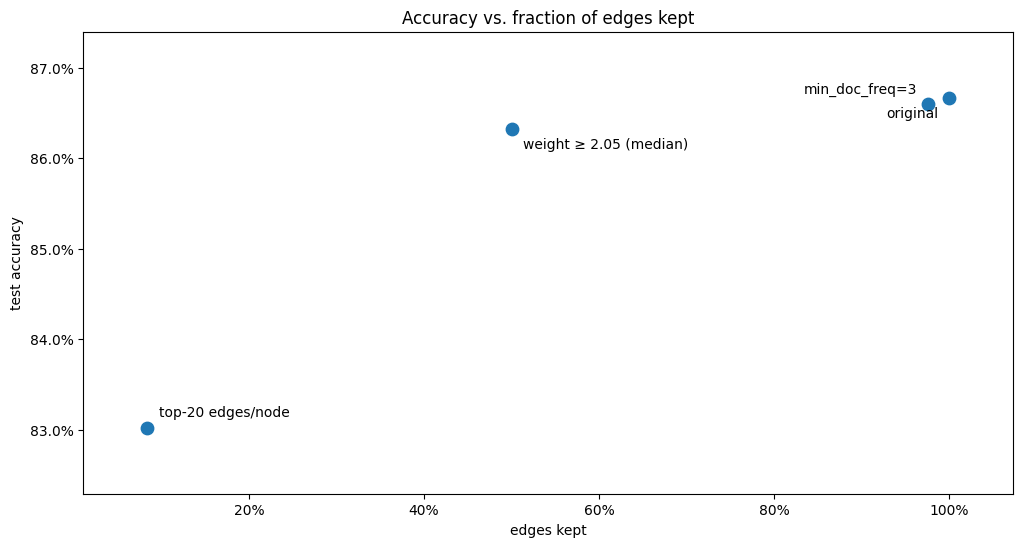

In [9]:
ax = summary.plot.scatter(x="edges kept", y="test_accuracy", s=80, figsize=(12, 6),
                          title="Accuracy vs. fraction of edges kept")
for k, (name, row) in enumerate(summary.iterrows()):
    right_side = row["edges kept"] > 0.9            # label to the left of points near 100%
    ax.annotate(name, (row["edges kept"], row.test_accuracy), textcoords="offset points",
                xytext=(-8 if right_side else 8, 8 if k % 2 else -14),
                ha="right" if right_side else "left")
ax.set_ylabel("test accuracy")
ax.margins(x=0.08, y=0.2)
ax.xaxis.set_major_formatter("{x:.0%}")
ax.yaxis.set_major_formatter("{x:.1%}");

## What the numbers say

On our GPU run (seed 1234):

* `min_doc_freq=3` removed about 600 rare words and **lost almost nothing** (86.6% vs
  86.7%). Fewer nodes means less memory, because the dense GCN grows with the
  square of the node count.
* Dropping the weaker half of the edges (keeping $w \geq$ median) cost only about
  **0.3 points** (86.3%). Moderate pruning is safe.
* `top-20 edges/node` kept only **8%** of the edges, but accuracy dropped by
  about **3.6 points** (83.0%).
* Compare that with tutorial 3: counted as here (document–word edges in both
  directions), the **Word2Vec RWF** graph has about 556 k entries, 12% of the 4.8 M
  (its builder reports 279,559 of 4,534,779 edges, about 6%), and it lost only about **1 point**.

The difference is *which* edges go. `top-k` treats all edges alike, so documents
with more than 20 words lose document–word edges. The
RWF removes word–word edges only and keeps every document–word edge, and
tutorial 3 showed that on this corpus those edges carry most of the signal.

## Takeaways

* **Measure first.** Graph statistics take seconds; training takes minutes.
* **Prune words, not just edges.** `min_doc_freq` is a safe first step.
* For an order-of-magnitude smaller graph, **change the builder** (tutorial 3)
  rather than pruning TF-IDF + PMI.
* **Keep the document–word edges.** Filters that remove them, like `top-k`, cost
  the most accuracy.
* Refinement works with any builder: pass `refinement_config` together with `builder`.

**Next:** so far we have used a benchmark. [5 · Bring your own corpus](https://vitormeriat.github.io/text4gcn/tutorials/05_bring_your_own_corpus/)
shows how to prepare your own data, in any language.